# 10 - The drift model, and the drifted datasets

Block 1 asks what happens when the scan positions are not where the scan generator says
they are. This notebook defines the drift, applies it, regenerates the datacubes on the
displaced positions, and then looks at what it did.

## The model

For scan position $k$ in acquisition order, at time $t_k = k\tau$:

$$\mathbf{r}_k = \mathbf{r}_k^{\mathrm{grid}} \;+\; \mathbf{v}\,t_k \;+\; \boldsymbol{\xi}_k,
\qquad \boldsymbol{\xi}_k \sim \mathcal{N}(0, \sigma^2 I_2)$$

Two terms, deliberately: a **constant-velocity stage drift** $\mathbf{v}$, and an
**i.i.d. Gaussian per-position jitter** $\sigma$.

| parameter | value | where it comes from |
|---|---|---|
| $\sigma$ | $0.25\ \mathrm{\AA}$ | Athena WSe2 survey: affine-removed per-point jitter 0.52-0.78 px at 0.43 Å step = 0.22-0.34 Å, against a 0.05 px refinement floor |
| $v$ | $0.5\ \mathrm{\AA/s}$ | a typical well-settled stage (0.1 excellent, 2.0 stressed) |
| $\theta$ | $30^\circ$ | so the drift is not accidentally aligned with a scan axis |
| $\tau$ | $49.60\ \mathrm{\mu s}$ | Pari's dwell |

Acquisition order is **unidirectional with flyback**. Pari's metadata does not record
whether the real scan was unidirectional or serpentine, so this is a stated assumption,
not a recovered fact. Serpentine is a sign flip on every odd row and is a one-line change
below.

**The dwell is held fixed across the three doses**, which means the dose difference is a
beam-current difference (428 pA at $10^6$, 43 pA at $10^5$, against Pari's 156 pA - all
ordinary currents). This matters here in a way it did not in block 0: drift is a function
of *time*, so had we instead set the dose by varying the dwell, the $10^5$ dataset would
be a 10x faster scan drifting 10x less, and low dose would look spuriously good. Fixing
$\tau$ keeps dose and drift orthogonal.

## Why the two terms behave completely differently

A constant-velocity drift is **almost exactly an affine distortion of the scan**: position
index maps linearly to time, so a displacement linear in time is linear in (row, column) -
a shear plus a dilation. That is precisely the part a position-refinement affine fit
removes, and it is why the Athena survey reports affine and per-point residual separately.

It goes further than that here. The checkerboard puts the two "on" samples of each
$2\times2$ cell on the diagonal and the two "off" samples on the anti-diagonal, and those
two pairs have **identical mean acquisition time**:

$$\tfrac{1}{2}\left[2IN{+}2J \;+\; (2I{+}1)N{+}2J{+}1\right] \;=\;
  \tfrac{1}{2}\left[2IN{+}2J{+}1 \;+\; (2I{+}1)N{+}2J\right]$$

So after block averaging, **the ramp is exactly common-mode between the two channels** -
verified to machine precision below. The two states are displaced relative to each other
by the jitter alone, at $\sigma = 0.25\ \mathrm{\AA}$ per axis, which is 0.69 of a `pari`
step and 1.52 of a `fine` step.

Two consequences, both tested at the end of this notebook:

* The relative on/off displacement has **essentially zero mean**, so a *global*
  registration between the channels has nothing to remove. The jitter is per-cell and
  random; it is not a shift.
* The ramp still distorts both channels identically, so it shows up when the drifted
  images are compared against the **ideal** ones - and there registration does work.

## What is deliberately not in it

The model has power at zero frequency (the ramp) and at the Nyquist (white jitter) and
**nothing in between**, whereas a real stage wanders. The honest third term is a random
walk / Ornstein-Uhlenbeck with one correlation-time knob. It is left out until the simple
version has said something; it is the first place to look if block 1 comes out too clean.

## What it writes

Per tag: `data/drifted_{tag}_geometry.npz` (carrying the nominal positions the methods
will assume, the true positions, and the applied drift field) and
`data/drifted_{tag}_merged_dose_{inf,1e6,1e5}.npy`.

In [1]:
import json
import pickle
import sys
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from scipy.ndimage import map_coordinates, fourier_shift

import abtem
from abtem.core.energy import energy2sigma
from abtem.potentials.iam import PotentialArray
from abtem.scan import CustomScan

NOTEBOOK_DIR = Path.cwd()
DATA_DIR = NOTEBOOK_DIR / "data"
DATA_DIR.mkdir(exist_ok=True)
PHASE_DIR = NOTEBOOK_DIR.parent / "hbn_bcenters_data"
sys.path.insert(0, str(NOTEBOOK_DIR.parent))

import method_wrappers as mw
from quantem.core.datastructures import Dataset4d
from quantem.core.utils.diffractive_imaging_utils import fit_probe_circle
from quantem.diffractive_imaging.direct_ptychography import DirectPtychography

try:
    import cupy
    abtem.config.set({"device": "gpu"})
    ABTEM_DEVICE = "gpu"
    print("abtem", abtem.__version__, "on gpu via cupy", cupy.__version__,
          "-", cupy.cuda.runtime.getDeviceProperties(0)["name"].decode())
except Exception as exc:
    abtem.config.set({"device": "cpu"})
    ABTEM_DEVICE = "cpu"
    print(f"abtem {abtem.__version__} on CPU - cupy unavailable ({exc}).")


def to_numpy(array):
    """abTEM hands back CuPy arrays on the GPU; numpy refuses to convert them implicitly."""
    return array.get() if hasattr(array, "get") else np.asarray(array)


print("phases :", PHASE_DIR)
print("out    :", DATA_DIR)

cuda:0
abtem 1.0.10 on gpu via cupy 14.2.0 - NVIDIA GeForce RTX 5090
phases : /home/rotem/ptycho_light/quantem/scripts/hbn_bcenters_data
out    : /home/rotem/ptycho_light/quantem/scripts/time_dependent_noise/data


## Configuration

The beam, camera, cell and scan are **identical to notebook 00** - block 1 differs from
block 0 in the scan positions and nothing else, so anything that changes downstream is
attributable to the drift. The drift parameters are the only new block.

In [2]:
# --- beam and camera, from Pari (identical to 00) ------------------------------
ACC_VOLTAGE_EV        = 300e3
PROBE_SEMIANGLE_MRAD  = 30.0
PROBE_DEFOCUS_ANG     = 654.0      # quantEM/abTEM sign; Pari quotes C10 = -654 A
ARINA_PITCH_MRAD      = 0.54657
ARINA_HALF_ANGLE_MRAD = 52.5

# --- the simulation cell, ours (identical to 00) -------------------------------
CELL_EXTENT_ANG   = 180.1          # = 36.02 * DETECTOR_BIN, for an exact bin
N_OBJECT_PX       = 1800           # 5-smooth, so the FFTs are fast
DETECTOR_BIN      = 5
SLICE_THICKNESS_ANG = 1.0

SCAN_CONFIGS = {
    "pari": dict(step_ang=0.36388, extent_ang=60.0),
    "fine": dict(step_ang=0.1641,  extent_ang=30.0),
}

TAPER_INNER_ANG, TAPER_OUTER_ANG = 6.0, 9.0
A_HBN, N_HBN_CELLS = 2.506, 6
DOSES = {"inf": None, "1e6": 1e6, "1e5": 1e5}

SCAN_CHUNK = 1024
RANDOM_SEED = 0

# --- the drift model, new in block 1 -------------------------------------------
DWELL_S          = 49.60e-6        # Pari's dwell, held fixed across all doses
DRIFT_V_ANG_S    = 0.5             # constant stage velocity; 0.1 excellent, 2.0 stressed
DRIFT_ANGLE_DEG  = 30.0            # not aligned with a scan axis
JITTER_SIGMA_ANG = 0.25            # Athena measured 0.22-0.34 A, floor 0.022 A
SERPENTINE       = False           # unidirectional with flyback
DRIFT_SEED       = 12345           # independent of the Poisson seed

# the diagnostic at the end runs at the optimal dose, so the figures show drift and not
# shot noise; the numeric table at the very end covers all three.
DIAG_DOSE_KEY = "inf"

# Registration search window. The object is a periodic lattice, so a global shift is only
# determined modulo a lattice vector; the search must stay inside half the hBN constant
# (a/2 = 1.253 A) or it locks onto an alias. Measured: with the full search it reported
# -16, -28 A, which is one 6x6 supercell (15.04 A), not a drift.
MAX_REG_SHIFT_ANG = 1.0

OBJECT_DX_ANG = CELL_EXTENT_ANG / N_OBJECT_PX

print(f"object : {N_OBJECT_PX} x {N_OBJECT_PX} px, {OBJECT_DX_ANG:.6f} A/px, "
      f"{CELL_EXTENT_ANG} A")
assert abs(CELL_EXTENT_ANG - 36.02 * DETECTOR_BIN) < 0.05, \
    "cell and bin are inconsistent; the binned pitch will not be ARINA's"

print(f"\ndrift  : v = {DRIFT_V_ANG_S} A/s at {DRIFT_ANGLE_DEG} deg, "
      f"sigma = {JITTER_SIGMA_ANG} A, dwell = {DWELL_S*1e6:.2f} us, "
      f"{'serpentine' if SERPENTINE else 'unidirectional'}")
for tag, cfg in SCAN_CONFIGS.items():
    n = int(np.floor(cfg["extent_ang"] / cfg["step_ang"]))
    frame_s = n * n * DWELL_S
    ramp_a = DRIFT_V_ANG_S * frame_s
    print(f"  {tag:5s}: {n}^2 positions, frame {frame_s:.4f} s, row {n*DWELL_S*1e3:.3f} ms")
    print(f"         ramp over frame {ramp_a:.4f} A = {ramp_a/cfg['step_ang']:5.2f} steps, "
          f"across one row {DRIFT_V_ANG_S*n*DWELL_S:.5f} A")
    print(f"         jitter {JITTER_SIGMA_ANG} A = {JITTER_SIGMA_ANG/cfg['step_ang']:.2f} steps")

object : 1800 x 1800 px, 0.100056 A/px, 180.1 A

drift  : v = 0.5 A/s at 30.0 deg, sigma = 0.25 A, dwell = 49.60 us, unidirectional
  pari : 164^2 positions, frame 1.3340 s, row 8.134 ms
         ramp over frame 0.6670 A =  1.83 steps, across one row 0.00407 A
         jitter 0.25 A = 0.69 steps
  fine : 182^2 positions, frame 1.6430 s, row 9.027 ms
         ramp over frame 0.8215 A =  5.01 steps, across one row 0.00451 A
         jitter 0.25 A = 1.52 steps


In [3]:
probe = abtem.Probe(
    energy=ACC_VOLTAGE_EV,
    semiangle_cutoff=PROBE_SEMIANGLE_MRAD,
    defocus=PROBE_DEFOCUS_ANG,
    extent=CELL_EXTENT_ANG,
    gpts=N_OBJECT_PX,
)
wavelength_ang = float(probe.wavelength)
DETECTOR_PITCH_MRAD = wavelength_ang / CELL_EXTENT_ANG * 1e3
binned_pitch_mrad = DETECTOR_PITCH_MRAD * DETECTOR_BIN

n_detector_binned = int(round(2 * ARINA_HALF_ANGLE_MRAD / binned_pitch_mrad))
n_detector_native = n_detector_binned * DETECTOR_BIN
crop_half_angle_mrad = n_detector_native / 2 * DETECTOR_PITCH_MRAD
antialias_mrad = float(probe.cutoff_angles[0])
SCAN_ORIGIN_OFFSET_ANG = (N_OBJECT_PX // 2) * OBJECT_DX_ANG

_built = to_numpy(probe.build(
    scan=[(SCAN_ORIGIN_OFFSET_ANG, SCAN_ORIGIN_OFFSET_ANG)]).compute().array)
probe_at_centre = _built if _built.ndim == 2 else _built[0]
probe_intensity = np.abs(probe_at_centre) ** 2
peak_i, peak_j = np.unravel_index(probe_intensity.argmax(), probe_intensity.shape)
rad = np.hypot((np.arange(N_OBJECT_PX)[:, None] - peak_i) * OBJECT_DX_ANG,
               (np.arange(N_OBJECT_PX)[None, :] - peak_j) * OBJECT_DX_ANG)
order = np.argsort(rad.ravel())
cumulative = np.cumsum(probe_intensity.ravel()[order]) / probe_intensity.sum()
r50 = rad.ravel()[order][np.searchsorted(cumulative, 0.50)]
r90 = rad.ravel()[order][np.searchsorted(cumulative, 0.90)]

print(f"wavelength     : {wavelength_ang:.6f} A")
print(f"binned pitch   : {binned_pitch_mrad:.6f} mrad/px (ARINA {ARINA_PITCH_MRAD})")
print(f"detector       : {n_detector_native} native -> {n_detector_binned} binned px, "
      f"+/-{crop_half_angle_mrad:.2f} mrad")
print(f"probe radius   : 50% {r50:.2f} A, 90% {r90:.2f} A")

assert crop_half_angle_mrad < antialias_mrad, "crop reaches past the antialias limit"
assert abs(binned_pitch_mrad / ARINA_PITCH_MRAD - 1) < 0.01, "binned pitch is not ARINA's"
assert r90 < CELL_EXTENT_ANG / 6, "probe is wrapping in the cell"

# the drifted scan wanders outside the nominal box, so the margin check has to allow for it
_max_drift = DRIFT_V_ANG_S * max(
    int(np.floor(c["extent_ang"] / c["step_ang"]))**2 * DWELL_S for c in SCAN_CONFIGS.values()
) + 4 * JITTER_SIGMA_ANG
for tag, cfg in SCAN_CONFIGS.items():
    illuminated = cfg["extent_ang"] + 4 * r90 + 2 * _max_drift
    print(f"  {tag:5s}: illuminated {illuminated:.1f} A of {CELL_EXTENT_ANG} A "
          f"(includes {_max_drift:.2f} A of drift margin)")
    assert illuminated < CELL_EXTENT_ANG, f"{tag}: drifted scan exceeds the cell"
print("the probe is compact and both drifted scans fit")

wavelength     : 0.019687 A
binned pitch   : 0.546571 mrad/px (ARINA 0.54657)
detector       : 960 native -> 192 binned px, +/-52.47 mrad
probe radius   : 50% 13.77 A, 90% 18.26 A
  pari : illuminated 136.7 A of 180.1 A (includes 1.82 A of drift margin)
  fine : illuminated 106.7 A of 180.1 A (includes 1.82 A of drift margin)
the probe is compact and both drifted scans fit


## The object

Identical to notebook 00: the hBN base phase tiled from the 6x6 supercell by lattice
translation, and the dipole excitation isolated with the raised-cosine taper at 6-9 Å.

In [4]:
U = N_HBN_CELLS * np.array([A_HBN, 0.0])
V = N_HBN_CELLS * np.array([A_HBN / 2.0, A_HBN * np.sqrt(3) / 2.0])

with open(PHASE_DIR / "bcenters_base_excited_phases_wide_fov.pkl", "rb") as handle:
    src = pickle.load(handle)
src_base = np.asarray(src["base"], np.float64)
src_delta = np.asarray(src["excited"], np.float64) - src_base
src_x, src_y = np.asarray(src["x"], np.float64), np.asarray(src["y"], np.float64)
src_dx, src_dy = src_x[1] - src_x[0], src_y[1] - src_y[0]

object_x_ang = (np.arange(N_OBJECT_PX) - N_OBJECT_PX // 2) * OBJECT_DX_ANG
XX, YY = np.meshgrid(object_x_ang, object_x_ang, indexing="ij")

lattice = np.column_stack((U, V))
frac = np.linalg.solve(lattice, np.vstack([XX.ravel(), YY.ravel()]))
frac -= np.round(frac)
wrapped = lattice @ frac

def _sample(image):
    return map_coordinates(
        image,
        np.vstack([(wrapped[0] - src_x[0]) / src_dx, (wrapped[1] - src_y[0]) / src_dy]),
        order=3, mode="nearest",
    ).reshape(XX.shape)

phase_base = _sample(src_base)
delta_tiled = _sample(src_delta)

i_neg = np.unravel_index(np.argmin(src_delta), src_delta.shape)
i_pos = np.unravel_index(np.argmax(src_delta), src_delta.shape)
blob_centre = 0.5 * np.array([src_x[i_neg[0]] + src_x[i_pos[0]],
                              src_y[i_neg[1]] + src_y[i_pos[1]]])
radius_from_blob = np.hypot(XX - blob_centre[0], YY - blob_centre[1])
taper = np.clip((radius_from_blob - TAPER_INNER_ANG)
                / (TAPER_OUTER_ANG - TAPER_INNER_ANG), 0.0, 1.0)
excitation_mask = 0.5 * (1.0 + np.cos(np.pi * taper))

delta_phi_true = delta_tiled * excitation_mask
phase_excited = phase_base + delta_phi_true

print(f"base phase : {phase_base.min():+.4f} .. {phase_base.max():+.4f} rad")
print(f"delta phi  : {delta_phi_true.min():+.5f} .. {delta_phi_true.max():+.5f} rad")
print(f"blob centre: ({blob_centre[0]:+.2f}, {blob_centre[1]:+.2f}) A")

base phase : -0.0372 .. +0.1991 rad
delta phi  : -0.02106 .. +0.01632 rad
blob centre: (+0.62, +1.78) A


In [5]:
sigma_interaction = float(energy2sigma(ACC_VOLTAGE_EV))


def make_potential(phase_image):
    return PotentialArray(
        array=(phase_image / (sigma_interaction * SLICE_THICKNESS_ANG))[None].astype(np.float32),
        slice_thickness=SLICE_THICKNESS_ANG,
        sampling=(OBJECT_DX_ANG, OBJECT_DX_ANG),
    )


def build_scan(step_ang, extent_ang):
    """Nominal scan positions: object frame (centred near the blob) and abTEM's."""
    axis = np.arange(int(np.floor(extent_ang / step_ang))) * step_ang
    axis = axis - axis.mean()
    grid_y, grid_x = np.meshgrid(axis, axis, indexing="ij")
    object_frame = np.stack([grid_y.ravel(), grid_x.ravel()], axis=1)
    return axis, object_frame, object_frame + SCAN_ORIGIN_OFFSET_ANG


detector = abtem.PixelatedDetector(max_angle=crop_half_angle_mrad)


def crop_and_bin(array):
    native = array.shape[-1]
    start = (native - n_detector_native) // 2
    if start > 0:
        array = array[..., start:start + n_detector_native,
                      start:start + n_detector_native]
    return array.reshape(*array.shape[:-2], n_detector_binned, DETECTOR_BIN,
                         n_detector_binned, DETECTOR_BIN).sum(axis=(-3, -1))


def simulate(potential, positions_abtem, label=""):
    out = np.empty((len(positions_abtem), n_detector_binned, n_detector_binned), np.float32)
    start_time = time.time()
    for lo in range(0, len(positions_abtem), SCAN_CHUNK):
        hi = min(lo + SCAN_CHUNK, len(positions_abtem))
        measurement = probe.scan(
            potential, scan=CustomScan(positions_abtem[lo:hi]), detectors=detector
        ).compute()
        out[lo:hi] = to_numpy(crop_and_bin(measurement.array)).astype(np.float32)
        del measurement
        print(f"    {label} {100*hi/len(positions_abtem):5.1f}%  "
              f"({time.time()-start_time:5.1f} s)")
    print(f"  {label} done: {len(positions_abtem):,} positions in "
          f"{time.time()-start_time:.1f} s")
    return out


def checkerboard_mask(shape):
    ii, jj = np.indices(shape)
    return ((ii + jj) % 2 == 0).astype(np.uint8)


def merge_and_dose(cube_off, cube_on, mask, dose, step_ang, rng):
    """Interlace the two states, then apply shot noise at `dose` e/A^2 (None = noiseless)."""
    merged = np.where(mask[..., None, None] == 1, cube_on, cube_off).astype(np.float32)
    merged /= merged.sum(axis=(2, 3), keepdims=True)
    if dose is not None:
        merged = rng.poisson(merged * dose * step_ang ** 2).astype(np.float32)
        total = merged.sum(axis=(2, 3), keepdims=True)
        merged /= np.where(total > 0, total, 1.0)
    return merged


potential_base = make_potential(phase_base)
potential_excited = make_potential(phase_excited)
print("potentials built;", f"abTEM device = {ABTEM_DEVICE}")

potentials built; abTEM device = gpu


## The drift field

`build_drift` returns the displacement applied to every scan position, split into its
ramp and jitter parts so each can be inspected on its own. The assertions below are the
claims from the header, checked numerically rather than asserted in prose.

In [6]:
def acquisition_order(n_scan, serpentine=SERPENTINE):
    """Map (row, col) -> acquisition index. Unidirectional, or serpentine (odd rows
    reversed). Returns an (n, n) integer array of time indices."""
    order = np.empty((n_scan, n_scan), dtype=np.int64)
    for i in range(n_scan):
        cols = np.arange(n_scan)
        if serpentine and i % 2 == 1:
            cols = cols[::-1]
        order[i, cols] = i * n_scan + np.arange(n_scan)
    return order


def build_drift(n_scan, seed):
    """Ramp + i.i.d. Gaussian jitter, in Angstrom, shaped (n, n, 2) as (dy, dx)."""
    order = acquisition_order(n_scan)
    t = order * DWELL_S
    direction = np.array([np.cos(np.deg2rad(DRIFT_ANGLE_DEG)),
                          np.sin(np.deg2rad(DRIFT_ANGLE_DEG))])
    ramp = t[..., None] * DRIFT_V_ANG_S * direction
    jitter = np.random.default_rng(seed).normal(0.0, JITTER_SIGMA_ANG, (n_scan, n_scan, 2))
    return ramp, jitter, order


def deinterlace(array):
    """Split a checkerboard-interlaced array into (off, on) on the coarse 2x2 grid.

    mask[i, j] = (i + j) % 2 == 0, so within each 2x2 cell the *on* samples are the
    diagonal and the *off* samples the anti-diagonal. Equivalent to
    method_wrappers.block_average_checkerboard, vectorised."""
    on = 0.5 * (array[0::2, 0::2] + array[1::2, 1::2])
    off = 0.5 * (array[0::2, 1::2] + array[1::2, 0::2])
    return off, on


drift_fields = {}
for tag, cfg in SCAN_CONFIGS.items():
    n_scan = int(np.floor(cfg["extent_ang"] / cfg["step_ang"]))
    ramp, jitter, order = build_drift(n_scan, DRIFT_SEED + list(SCAN_CONFIGS).index(tag))
    total = ramp + jitter
    drift_fields[tag] = dict(ramp=ramp, jitter=jitter, total=total, order=order,
                             n_scan=n_scan)

    off_r, on_r = deinterlace(ramp)
    off_t, on_t = deinterlace(total)
    rel_ramp, rel_total = on_r - off_r, on_t - off_t

    print(f"\n=== {tag}: {n_scan}^2 positions ===")
    print(f"  ramp        : {np.hypot(*ramp[-1, -1]):.4f} A end-to-end "
          f"= {np.hypot(*ramp[-1, -1])/cfg['step_ang']:.2f} steps")
    print(f"  jitter      : rms ({jitter[...,0].std():.4f}, {jitter[...,1].std():.4f}) A "
          f"(target {JITTER_SIGMA_ANG})")
    print(f"  on - off after block averaging:")
    print(f"    ramp only : max |rel| = {np.abs(rel_ramp).max():.2e} A   <- common-mode")
    # the mean of a zero-mean field over n cells is only zero to its own standard error
    n_cells = rel_total[..., 0].size
    sem = JITTER_SIGMA_ANG / np.sqrt(n_cells)
    print(f"    full      : mean ({rel_total[...,0].mean():+.5f}, "
          f"{rel_total[...,1].mean():+.5f}) A  (s.e. {sem:.5f}), "
          f"rms ({rel_total[...,0].std():.4f}, {rel_total[...,1].std():.4f}) A")

    # the two claims from the header
    assert np.abs(rel_ramp).max() < 1e-9, \
        "the ramp is not common-mode between the channels - check the acquisition order"
    assert np.abs(rel_total.mean(axis=(0, 1))).max() < 5 * sem, \
        "the relative on/off displacement has a mean beyond chance - a global "\
        "registration could remove part of it"
    assert abs(rel_total[..., 0].std() / JITTER_SIGMA_ANG - 1) < 0.15, \
        "relative jitter is not sigma as derived"

print("\nboth claims hold: the ramp cancels between channels, the jitter does not.")


=== pari: 164^2 positions ===
  ramp        : 0.6670 A end-to-end = 1.83 steps
  jitter      : rms (0.2471, 0.2510) A (target 0.25)
  on - off after block averaging:
    ramp only : max |rel| = 1.11e-16 A   <- common-mode
    full      : mean (+0.00350, +0.00363) A  (s.e. 0.00305), rms (0.2468, 0.2537) A

=== fine: 182^2 positions ===
  ramp        : 0.8215 A end-to-end = 5.01 steps
  jitter      : rms (0.2502, 0.2518) A (target 0.25)
  on - off after block averaging:
    ramp only : max |rel| = 1.11e-16 A   <- common-mode
    full      : mean (+0.00119, -0.00063) A  (s.e. 0.00275), rms (0.2506, 0.2502) A

both claims hold: the ramp cancels between channels, the jitter does not.


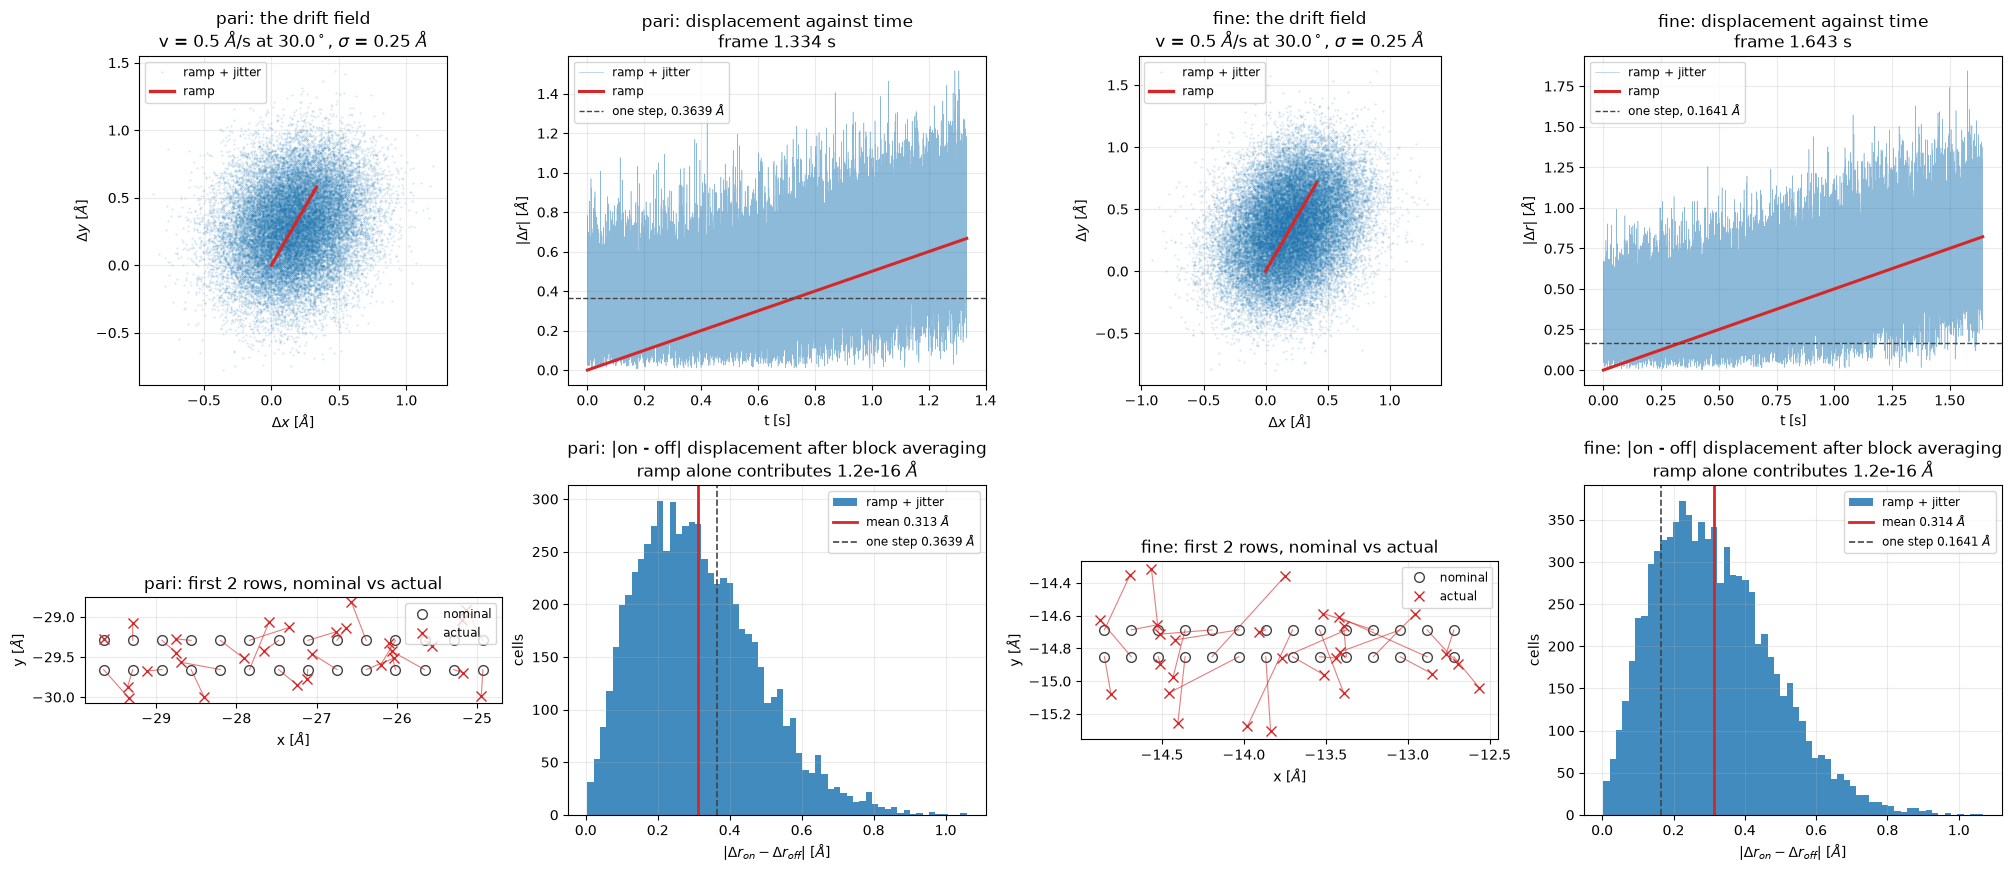

In [7]:
fig, axes = plt.subplots(2, len(SCAN_CONFIGS) * 2,
                         figsize=(5.0 * len(SCAN_CONFIGS) * 2, 8.6),
                         constrained_layout=True)

for col, (tag, cfg) in enumerate(SCAN_CONFIGS.items()):
    d = drift_fields[tag]
    n_scan, step = d["n_scan"], cfg["step_ang"]
    k = d["order"].ravel()
    srt = np.argsort(k)
    ramp_t = d["ramp"].reshape(-1, 2)[srt]
    total_t = d["total"].reshape(-1, 2)[srt]
    t_s = np.sort(k) * DWELL_S

    ax = axes[0][2 * col]
    ax.plot(total_t[:, 1], total_t[:, 0], ".", ms=0.7, alpha=0.25, color="#1f77b4",
            label="ramp + jitter")
    ax.plot(ramp_t[:, 1], ramp_t[:, 0], "-", lw=2.4, color="#d62728", label="ramp")
    ax.set_aspect("equal")
    ax.set_title(f"{tag}: the drift field\n"
                 f"v = {DRIFT_V_ANG_S} $\\AA$/s at {DRIFT_ANGLE_DEG}$^\\circ$, "
                 f"$\\sigma$ = {JITTER_SIGMA_ANG} $\\AA$")
    ax.set_xlabel(r"$\Delta x$ [$\AA$]"); ax.set_ylabel(r"$\Delta y$ [$\AA$]")
    ax.legend(fontsize=8.5, loc="upper left"); ax.grid(alpha=0.25)

    ax = axes[0][2 * col + 1]
    ax.plot(t_s, np.hypot(*total_t.T), lw=0.4, alpha=0.5, color="#1f77b4",
            label="ramp + jitter")
    ax.plot(t_s, np.hypot(*ramp_t.T), lw=2.2, color="#d62728", label="ramp")
    ax.axhline(step, color="#444", ls="--", lw=1.0, label=f"one step, {step:.4f} $\\AA$")
    ax.set_title(f"{tag}: displacement against time\nframe {n_scan**2*DWELL_S:.3f} s")
    ax.set_xlabel("t [s]"); ax.set_ylabel(r"$|\Delta r|$ [$\AA$]")
    ax.legend(fontsize=8.5); ax.grid(alpha=0.25)

    # nominal vs actual, zoomed into the first two rows
    ax = axes[1][2 * col]
    axis, nominal, _ = build_scan(cfg["step_ang"], cfg["extent_ang"])
    nominal = nominal.reshape(n_scan, n_scan, 2)
    actual = nominal + d["total"]
    sl = (slice(0, 2), slice(0, 14))
    ax.plot(nominal[sl][..., 1].ravel(), nominal[sl][..., 0].ravel(), "o", ms=7,
            mfc="none", mec="#444", label="nominal")
    ax.plot(actual[sl][..., 1].ravel(), actual[sl][..., 0].ravel(), "x", ms=7,
            color="#d62728", label="actual")
    for a, b in zip(nominal[sl].reshape(-1, 2), actual[sl].reshape(-1, 2)):
        ax.plot([a[1], b[1]], [a[0], b[0]], "-", lw=0.8, color="#d62728", alpha=0.6)
    ax.set_aspect("equal")
    ax.set_title(f"{tag}: first 2 rows, nominal vs actual")
    ax.set_xlabel(r"x [$\AA$]"); ax.set_ylabel(r"y [$\AA$]")
    ax.legend(fontsize=8.5); ax.grid(alpha=0.25)

    # the relative on-off displacement, which is what the subtraction actually sees
    ax = axes[1][2 * col + 1]
    off_t, on_t = deinterlace(d["total"])
    rel = np.hypot(*(on_t - off_t).transpose(2, 0, 1)).ravel()
    off_r, on_r = deinterlace(d["ramp"])
    rel_r = np.hypot(*(on_r - off_r).transpose(2, 0, 1)).ravel()
    ax.hist(rel, bins=60, color="#1f77b4", alpha=0.85, label="ramp + jitter")
    ax.axvline(rel.mean(), color="#d62728", lw=2.0,
               label=f"mean {rel.mean():.3f} $\\AA$")
    ax.axvline(step, color="#444", ls="--", lw=1.2, label=f"one step {step:.4f} $\\AA$")
    ax.set_title(f"{tag}: |on - off| displacement after block averaging\n"
                 f"ramp alone contributes {rel_r.max():.1e} $\\AA$")
    ax.set_xlabel(r"$|\Delta r_{on} - \Delta r_{off}|$ [$\AA$]"); ax.set_ylabel("cells")
    ax.legend(fontsize=8.5); ax.grid(alpha=0.25)

plt.show()

## Generate

Both states are simulated at the **same** drifted positions - the specimen drifts whether
the light is on or not - and interlaced afterwards, exactly as in notebook 00. The
positions handed to abTEM are the true ones; the positions written into the geometry file
as `scan_positions` are the **nominal** ones, because that is all a reconstruction knows.
The truth is saved alongside, under `scan_positions_true`, for notebook 19 to check
against.

In [8]:
results = {}

for tag, cfg in SCAN_CONFIGS.items():
    step_ang, extent_ang = cfg["step_ang"], cfg["extent_ang"]
    axis, scan_object, scan_abtem = build_scan(step_ang, extent_ang)
    n_scan = len(axis)
    d = drift_fields[tag]
    assert d["n_scan"] == n_scan, f"{tag}: drift field and scan disagree on size"

    drift_flat = d["total"].reshape(-1, 2)
    scan_abtem_drifted = scan_abtem + drift_flat
    scan_object_drifted = scan_object + drift_flat

    lo = scan_abtem_drifted.min() - 2 * r90
    hi = scan_abtem_drifted.max() + 2 * r90
    assert lo > 0 and hi < CELL_EXTENT_ANG, \
        f"{tag}: the drifted scan plus its probe falls outside the cell"

    print(f"\n=== {tag}: {n_scan} x {n_scan} = {n_scan**2:,} positions, drifted ===")
    print(f"  nominal extent {axis[0]:+.2f} .. {axis[-1]:+.2f} A")
    print(f"  drift applied  |dr| mean {np.hypot(*drift_flat.T).mean():.4f} A, "
          f"max {np.hypot(*drift_flat.T).max():.4f} A")
    print(f"  output cube: {n_scan**2 * n_detector_binned**2 * 4 / 1e9:.2f} GB float32")

    cube_base = simulate(potential_base, scan_abtem_drifted, f"{tag} base   ")
    cube_excited = simulate(potential_excited, scan_abtem_drifted, f"{tag} excited")
    cube_base = cube_base.reshape(n_scan, n_scan, n_detector_binned, n_detector_binned)
    cube_excited = cube_excited.reshape(n_scan, n_scan, n_detector_binned, n_detector_binned)

    rel = np.abs(cube_excited - cube_base).max() / cube_base.max()
    print(f"  largest excitation-induced change : {rel:.3e} of the brightest pixel")

    results[tag] = dict(axis=axis, scan_object=scan_object,
                        scan_object_drifted=scan_object_drifted, n_scan=n_scan,
                        cube_base=cube_base, cube_excited=cube_excited,
                        step_ang=step_ang, extent_ang=extent_ang)


=== pari: 164 x 164 = 26,896 positions, drifted ===
  nominal extent -29.66 .. +29.66 A
  drift applied  |dr| mean 0.4652 A, max 1.5170 A
  output cube: 3.97 GB float32


tasks:  21%|##1       | 12/56 [00:00<00:01, 23.60it/s]

    pari base      3.8%  (  4.9 s)


tasks:  23%|##3       | 13/56 [00:00<00:01, 25.06it/s]

    pari base      7.6%  (  9.7 s)


tasks:  23%|##3       | 13/56 [00:00<00:01, 25.01it/s]

... (233 outputs left out)

    fine excited  98.9%  (154.8 s)


tasks:  62%|######1   | 13/21 [00:00<00:00, 25.79it/s]

    fine excited 100.0%  (156.5 s)
  fine excited done: 33,124 positions in 156.5 s


  largest excitation-induced change : 1.396e-02 of the brightest pixel


In [9]:
rng = np.random.default_rng(RANDOM_SEED)

for tag, r in results.items():
    n_scan, step_ang = r["n_scan"], r["step_ang"]
    mask = checkerboard_mask((n_scan, n_scan))
    d = drift_fields[tag]
    scan_params = {
        "probe_energy": ACC_VOLTAGE_EV,
        "probe_semiangle": PROBE_SEMIANGLE_MRAD,
        "probe_defocus": PROBE_DEFOCUS_ANG,
        # the COARSE nominal step. A method does not know the positions drifted.
        "scan_step": 2 * step_ang,
    }
    drift_params = {
        "dwell_s": DWELL_S, "drift_v_ang_s": DRIFT_V_ANG_S,
        "drift_angle_deg": DRIFT_ANGLE_DEG, "jitter_sigma_ang": JITTER_SIGMA_ANG,
        "serpentine": SERPENTINE, "drift_seed": DRIFT_SEED,
    }
    np.savez_compressed(
        DATA_DIR / f"drifted_{tag}_geometry.npz",
        scan_mask=mask,
        scan_positions=r["scan_object"].astype(np.float32),          # nominal
        scan_positions_true=r["scan_object_drifted"].astype(np.float32),
        drift_total_ang=d["total"].astype(np.float32),
        drift_ramp_ang=d["ramp"].astype(np.float32),
        drift_jitter_ang=d["jitter"].astype(np.float32),
        acquisition_order=d["order"],
        drift_params_json=json.dumps(drift_params),
        scan_axis_ang=r["axis"].astype(np.float32),
        scan_params_json=json.dumps(scan_params),
        phase_base=phase_base.astype(np.float32),
        phase_excited=phase_excited.astype(np.float32),
        delta_phi_true=delta_phi_true.astype(np.float32),
        excitation_mask=excitation_mask.astype(np.float32),
        object_x_ang=object_x_ang.astype(np.float32),
        blob_centre_ang=blob_centre,
        object_dx_ang=OBJECT_DX_ANG,
        cell_extent_ang=CELL_EXTENT_ANG,
        detector_pitch_mrad=binned_pitch_mrad,
        detector_half_angle_mrad=crop_half_angle_mrad,
        wavelength_ang=wavelength_ang,
        scan_step_ang=step_ang,
        scan_extent_ang=r["extent_ang"],
        probe_r50_ang=r50, probe_r90_ang=r90,
    )
    print(f"wrote drifted_{tag}_geometry.npz")
    for key, dose in DOSES.items():
        merged = merge_and_dose(r["cube_base"], r["cube_excited"], mask, dose,
                                step_ang, rng)
        path = DATA_DIR / f"drifted_{tag}_merged_dose_{key}.npy"
        np.save(path, merged)
        print(f"  {path.name:40s} {path.stat().st_size/1e9:5.2f} GB")
        del merged

# the cubes are ~4 GB each and the diagnostics below reload from disk
for r in results.values():
    del r["cube_base"], r["cube_excited"]
print("\ndone")

wrote drifted_pari_geometry.npz


  drifted_pari_merged_dose_inf.npy          3.97 GB


  drifted_pari_merged_dose_1e6.npy          3.97 GB


  drifted_pari_merged_dose_1e5.npy          3.97 GB


wrote drifted_fine_geometry.npz


  drifted_fine_merged_dose_inf.npy          4.88 GB


  drifted_fine_merged_dose_1e6.npy          4.88 GB


  drifted_fine_merged_dose_1e5.npy          4.88 GB

done


## What the drift did: BF, DF and SSB

Three images per channel, all on the coarse $2\times2$-block-averaged grid that the
de-interlaced channels live on:

* **BF** - virtual bright field, the detector integrated inside the 30 mrad disc
* **DF** - virtual dark field, integrated outside it
* **SSB** - the single-sideband phase, reconstructed per channel through quanTEM's
  `DirectPtychography` (the baseband branch, so this is the object phase of that channel
  alone, not the carrier-demodulated $\Delta\varphi$ that `method_wrappers.direct_ssb`
  returns from the interlaced cube)

and two comparisons:

**A - the two states.** `on - off` within the drifted dataset, against the same difference
in the ideal dataset. This is the subtraction that method 1 performs, and it is where the
jitter bites.

**B - the two datasets.** drifted against ideal, channel by channel. This is where the
ramp shows up, because it distorts both channels equally and so cancels out of A entirely.

Registration is a single global sub-pixel shift, applied by Fourier shift. The point of
showing before and after is to establish *which* of the two comparisons a global
registration can actually repair.

**The search has to be bounded, and that is a physical constraint rather than a numerical
one.** The specimen is a periodic lattice, so the cross-correlation peaks at every lattice
vector and a free search returns whichever is tallest: run unbounded on these images it
reported a shift of $(-16.0, -28.5)\ \mathrm{\AA}$, which is one $6\times6$ supercell
(15.04 Å), not a displacement. The search is therefore restricted to
`MAX_REG_SHIFT_ANG` = 1.0 Å, inside half the hBN constant $a/2 = 1.253\ \mathrm{\AA}$.

The consequence is worth carrying into 19: **image registration on a periodic specimen
cannot measure a global drift larger than $a/2$.** Here the expected ramp is
$vT/2 = 0.33\ \mathrm{\AA}$ and there is room to spare, but at the stressed
$v = 2\ \mathrm{\AA/s}$ the mean ramp would be 1.33 Å and this diagnostic would alias.

This runs at `DIAG_DOSE_KEY` so the figures show drift rather than shot noise; the table
at the end repeats the numbers at every dose.

In [10]:
q_axis_mrad = (np.arange(n_detector_binned) - n_detector_binned / 2 + 0.5) * binned_pitch_mrad
QX, QY = np.meshgrid(q_axis_mrad, q_axis_mrad, indexing="ij")
Q = np.hypot(QX, QY)
BF_MASK = (Q <= PROBE_SEMIANGLE_MRAD).astype(np.float32)
DF_MASK = ((Q > PROBE_SEMIANGLE_MRAD) & (Q <= crop_half_angle_mrad)).astype(np.float32)
print(f"BF disc {int(BF_MASK.sum()):,} px, DF annulus {int(DF_MASK.sum()):,} px "
      f"of {n_detector_binned**2:,}")


def ssb_phase(cube, coarse_step, scan_params):
    """Single-sideband phase of one channel's datacube, on its own coarse grid."""
    _, _, probe_R = fit_probe_circle(cube.mean(axis=(0, 1)), show=False)
    mrad_per_px = scan_params["probe_semiangle"] / probe_R
    dset = Dataset4d.from_array(
        cube, sampling=(coarse_step, coarse_step, mrad_per_px, mrad_per_px),
        units=("A", "A", "mrad", "mrad"))
    ptycho = DirectPtychography.from_dataset4d(
        dset, energy=scan_params["probe_energy"],
        semiangle_cutoff=scan_params["probe_semiangle"],
        aberration_coefs={"defocus": scan_params["probe_defocus"]}, verbose=False)
    ptycho._preprocess()
    obj = mw._reconstruct_complex_ssb(ptycho, ptycho._vbf_fourier, force_dc=True)
    return np.angle(obj.detach().cpu().numpy())


def channel_images(path, coarse_step, scan_params):
    """BF, DF and SSB phase for each de-interlaced channel of a merged datacube."""
    merged = np.load(path)
    off_cube, on_cube = deinterlace(merged)
    del merged
    out = {}
    for name, cube in (("off", off_cube), ("on", on_cube)):
        out[("bf", name)] = np.einsum("ijkl,kl->ij", cube, BF_MASK)
        out[("df", name)] = np.einsum("ijkl,kl->ij", cube, DF_MASK)
        out[("ssb", name)] = ssb_phase(cube, coarse_step, scan_params)
    del off_cube, on_cube
    return out


def register(reference, moving, coarse_step, max_shift_ang=None):
    """Global sub-pixel shift aligning `moving` onto `reference`, searched only within
    `max_shift_ang`.

    The search has to be bounded. The specimen is a periodic lattice, so the
    cross-correlation has a peak at every lattice vector and an unbounded search happily
    returns one of them: on these images it reported a 'shift' of (-16.0, -28.5) A, which
    is one 6x6 supercell (15.04 A), not a displacement. Bounding it below a/2 = 1.253 A
    keeps the search in the central peak. Sub-pixel position comes from a parabolic fit on
    the 3x3 neighbourhood, which recovers known shifts to better than 0.1 px (~0.07 A)
    over the range of interest.
    """
    max_shift_px = (MAX_REG_SHIFT_ANG if max_shift_ang is None else max_shift_ang) / coarse_step
    a = reference - reference.mean()
    b = moving - moving.mean()
    cc = np.fft.fftshift(np.real(np.fft.ifft2(np.fft.fft2(b) * np.conj(np.fft.fft2(a)))))
    c0, c1 = cc.shape[0] // 2, cc.shape[1] // 2
    yy, xx = np.indices(cc.shape)
    search = np.where(np.hypot(yy - c0, xx - c1) <= max_shift_px, cc, -np.inf)
    p0, p1 = np.unravel_index(np.argmax(search), cc.shape)
    sub = np.zeros(2)
    for ax in (0, 1):
        lo, hi = [p0, p1], [p0, p1]
        lo[ax] -= 1
        hi[ax] += 1
        if 0 <= lo[ax] and hi[ax] < cc.shape[ax]:
            fm, f0, fp = cc[tuple(lo)], cc[p0, p1], cc[tuple(hi)]
            den = fm - 2 * f0 + fp
            if abs(den) > 1e-30:
                sub[ax] = np.clip(0.5 * (fm - fp) / den, -0.5, 0.5)
    shift = np.array([p0 - c0, p1 - c1], float) + sub
    aligned = np.real(np.fft.ifft2(fourier_shift(np.fft.fft2(moving), -shift)))
    return shift, aligned


MODALITIES = ["bf", "df", "ssb"]
MODALITY_LABEL = {"bf": "BF", "df": "DF", "ssb": "SSB phase"}

BF disc 9,484 px, DF annulus 19,484 px of 36,864


In [11]:
images = {}
t0 = time.time()
for tag, cfg in SCAN_CONFIGS.items():
    coarse_step = 2 * cfg["step_ang"]
    geom = np.load(DATA_DIR / f"ideal_{tag}_geometry.npz")
    sp = json.loads(str(geom["scan_params_json"]))
    for dose_key in DOSES:
        for kind in ("ideal", "drifted"):
            path = DATA_DIR / f"{kind}_{tag}_merged_dose_{dose_key}.npy"
            images[(tag, kind, dose_key)] = channel_images(path, coarse_step, sp)
            print(f"  {kind:8s} {tag:5s} dose {dose_key:>3s}  ({time.time()-t0:6.1f} s)")

coarse_axis = {tag: 0.5 * (results[tag]["axis"][0::2] + results[tag]["axis"][1::2])
               for tag in SCAN_CONFIGS}
print(f"\nall images in {time.time()-t0:.1f} s")

  ideal    pari  dose inf  (   9.5 s)


  drifted  pari  dose inf  (  19.0 s)


  ideal    pari  dose 1e6  (  28.5 s)


  drifted  pari  dose 1e6  (  38.2 s)


  ideal    pari  dose 1e5  (  47.8 s)


  drifted  pari  dose 1e5  (  57.4 s)


... (2 outputs left out)

  ideal    fine  dose 1e6  (  92.5 s)


  drifted  fine  dose 1e6  ( 104.0 s)


  ideal    fine  dose 1e5  ( 115.5 s)


  drifted  fine  dose 1e5  ( 127.0 s)

all images in 127.0 s


### Comparison A - the two states

`on - off`, which is the excitation the subtraction is meant to recover. The ideal
dataset's version is the reference answer in the left column; the drifted dataset's
follows, raw and then after a global registration of the on channel onto the off channel.
All three panels in a row share the ideal column's colour scale, so they are directly
comparable.

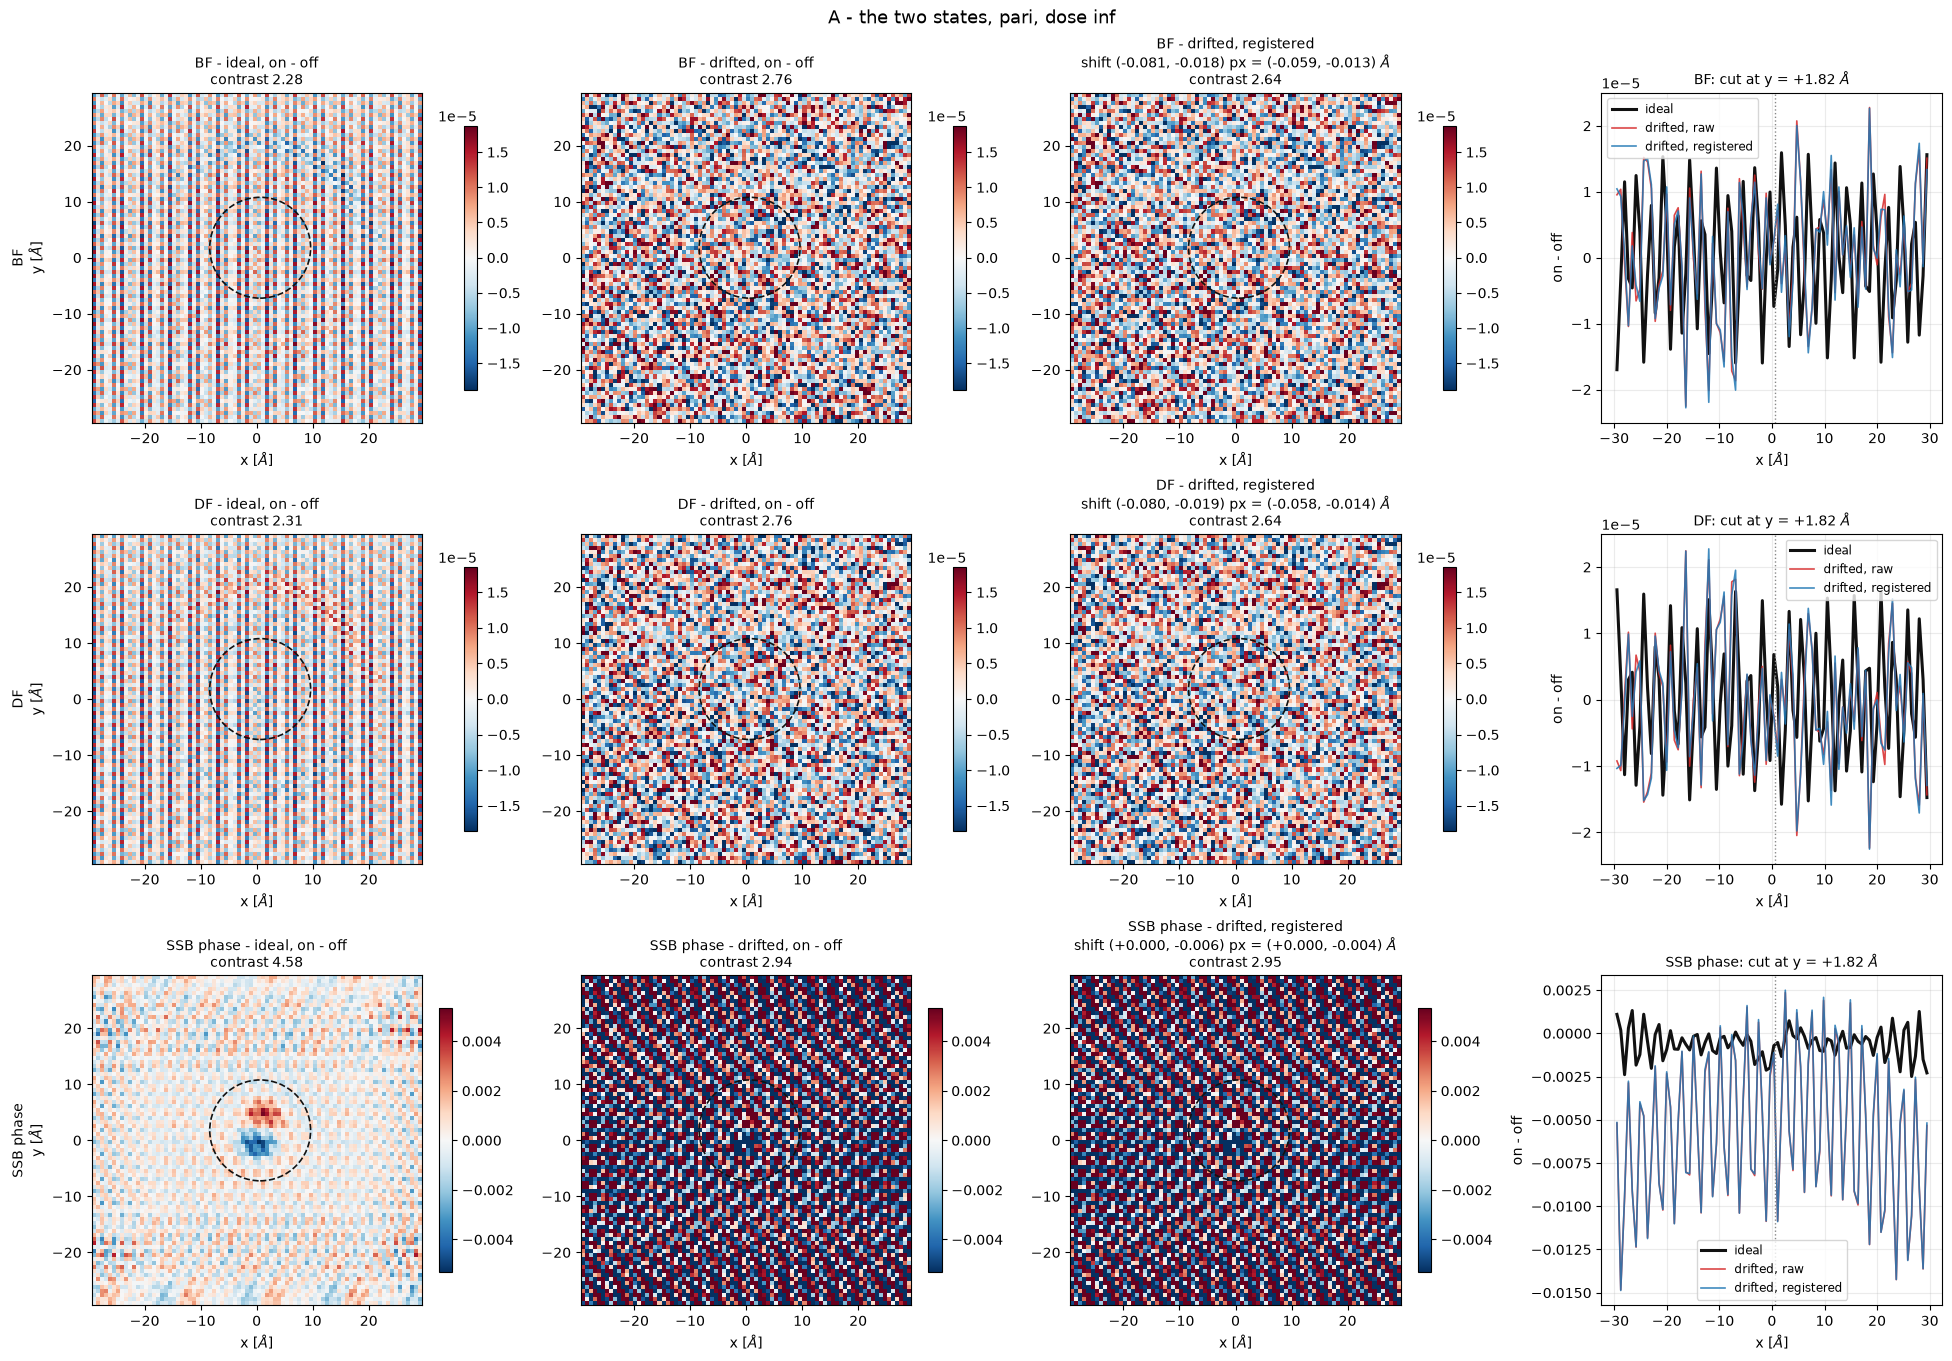

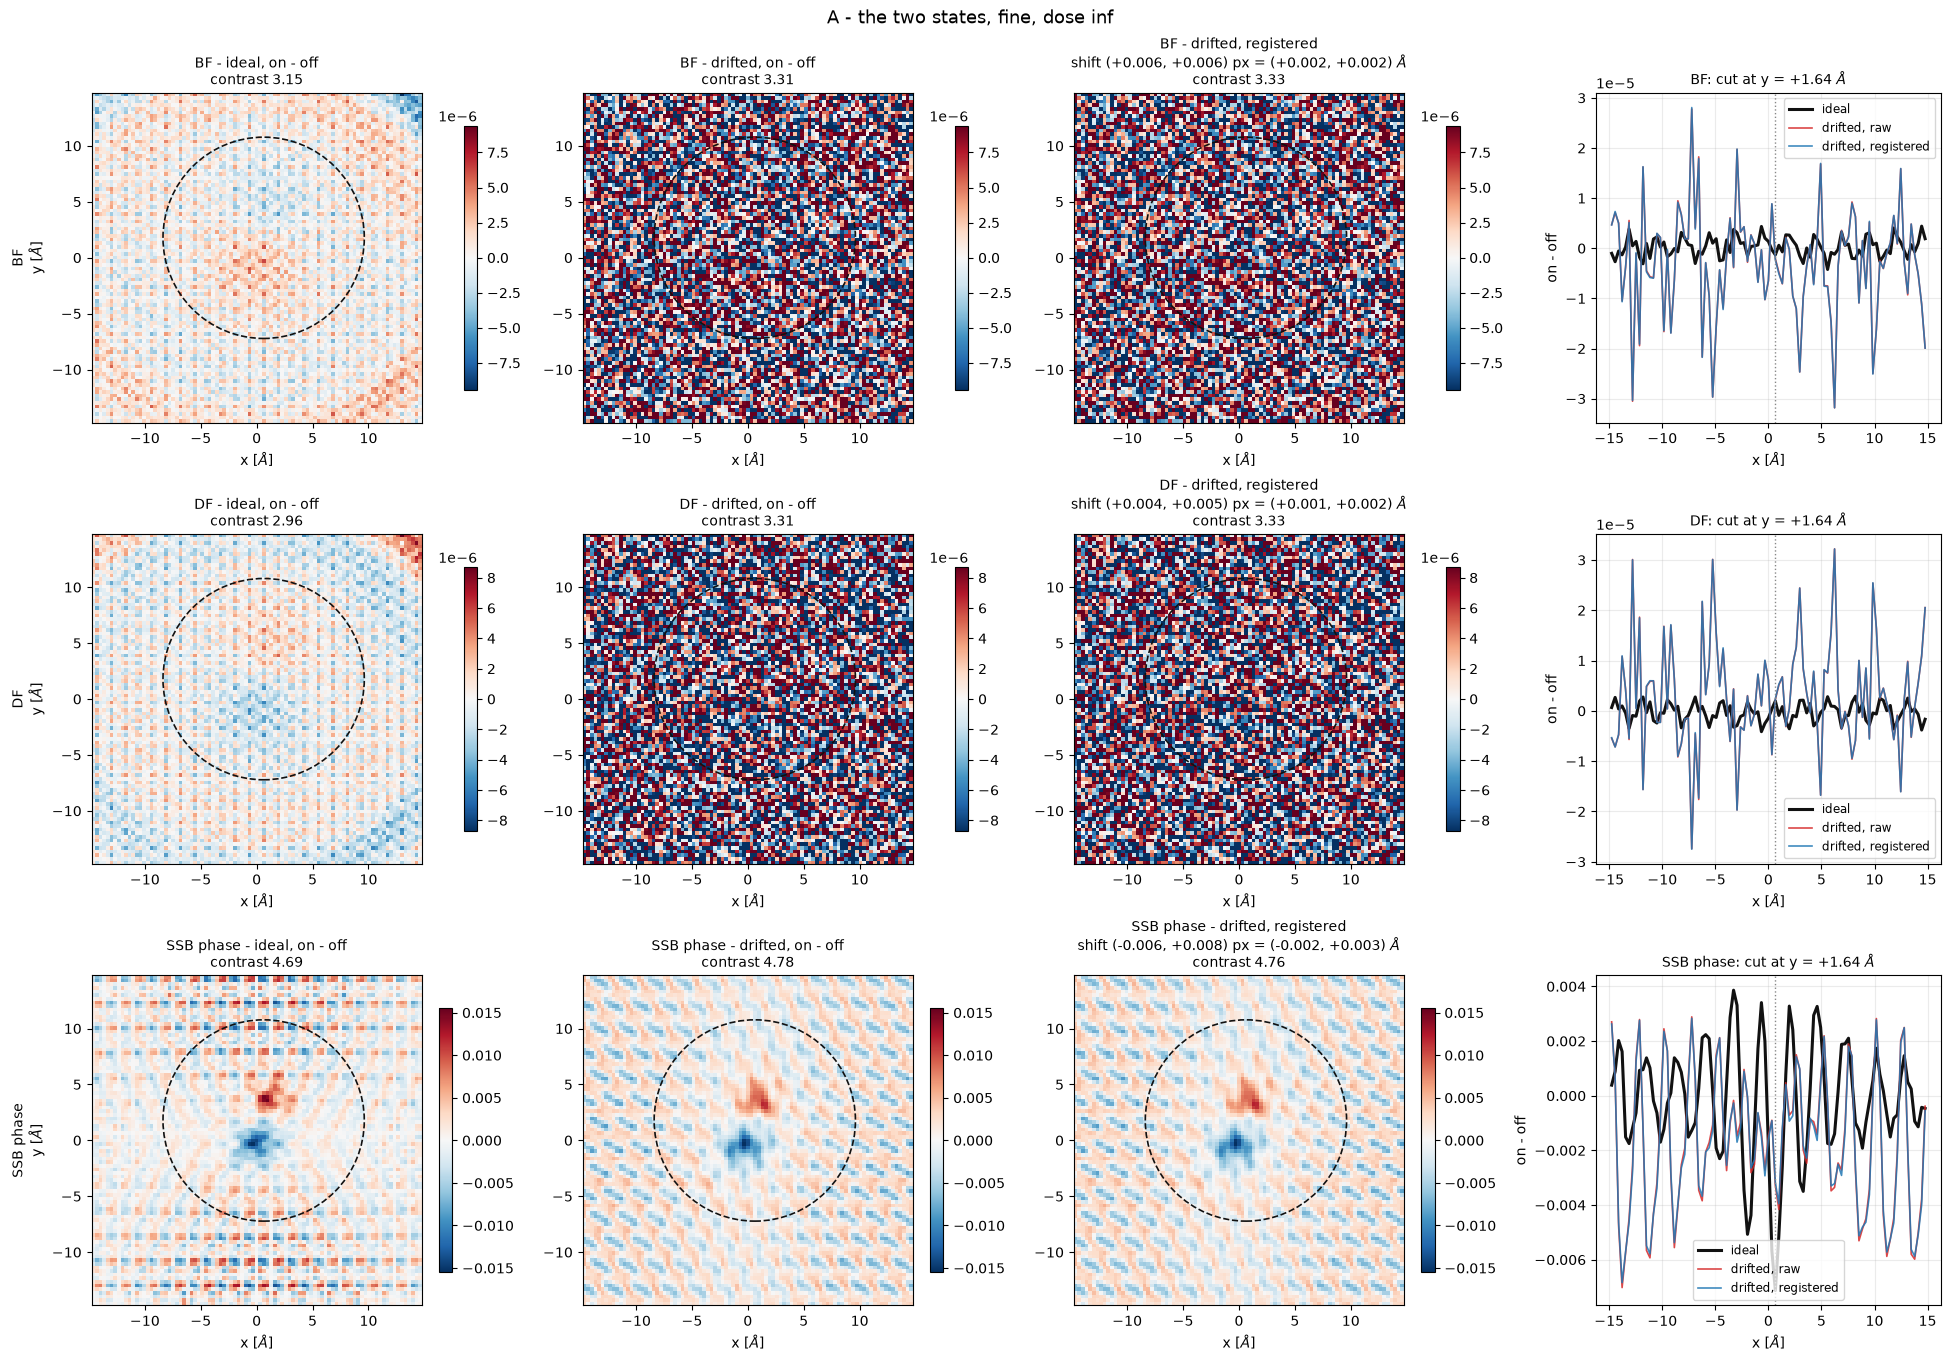

In [12]:
def blob_cut_index(tag):
    """Coarse-grid index of the row through the blob centre (constant y)."""
    return int(np.argmin(np.abs(coarse_axis[tag] - blob_centre[1])))


def excitation_contrast(diff, tag):
    """Peak |diff| near the blob against the rms far from it."""
    ca = coarse_axis[tag]
    gx, gy = np.meshgrid(ca, ca, indexing="ij")
    r = np.hypot(gx - blob_centre[0], gy - blob_centre[1])
    near, far = r <= TAPER_OUTER_ANG, r > TAPER_OUTER_ANG + 6.0
    if not near.any() or not far.any():
        return np.nan
    return np.abs(diff[near]).max() / diff[far].std()


shifts_A = {}
for tag in SCAN_CONFIGS:
    ca = coarse_axis[tag]
    ext = [ca[0], ca[-1], ca[0], ca[-1]]
    fig, axes = plt.subplots(len(MODALITIES), 4,
                             figsize=(19.5, 4.5 * len(MODALITIES)),
                             constrained_layout=True)
    for row, mod in enumerate(MODALITIES):
        ideal = images[(tag, "ideal", DIAG_DOSE_KEY)]
        drift = images[(tag, "drifted", DIAG_DOSE_KEY)]
        d_ideal = ideal[(mod, "on")] - ideal[(mod, "off")]
        d_raw = drift[(mod, "on")] - drift[(mod, "off")]
        shift, on_reg = register(drift[(mod, "off")], drift[(mod, "on")],
                                 2 * SCAN_CONFIGS[tag]["step_ang"])
        d_reg = on_reg - drift[(mod, "off")]
        shifts_A[(tag, mod)] = shift

        lim = np.abs(d_ideal).max()
        panels = [(d_ideal, "ideal, on - off"),
                  (d_raw, "drifted, on - off"),
                  (d_reg, f"drifted, registered\nshift ({shift[0]:+.3f}, {shift[1]:+.3f}) px"
                          f" = ({shift[0]*2*SCAN_CONFIGS[tag]['step_ang']:+.3f}, "
                          f"{shift[1]*2*SCAN_CONFIGS[tag]['step_ang']:+.3f}) $\\AA$")]
        for col, (img, title) in enumerate(panels):
            ax = axes[row][col]
            im = ax.imshow(img.T, extent=ext, origin="lower", cmap="RdBu_r",
                           vmin=-lim, vmax=lim)
            ax.add_patch(Circle(blob_centre, TAPER_OUTER_ANG, fill=False,
                                ec="#111111", lw=1.2, ls="--"))
            ax.set_title(f"{MODALITY_LABEL[mod]} - {title}\n"
                         f"contrast {excitation_contrast(img, tag):.2f}", fontsize=10)
            ax.set_xlabel(r"x [$\AA$]")
            if col == 0:
                ax.set_ylabel(f"{MODALITY_LABEL[mod]}\n" + r"y [$\AA$]")
            fig.colorbar(im, ax=ax, shrink=0.8)

        ax = axes[row][3]
        j0 = blob_cut_index(tag)
        ax.plot(ca, d_ideal[:, j0], lw=2.2, color="#111111", label="ideal")
        ax.plot(ca, d_raw[:, j0], lw=1.2, color="#d62728", alpha=0.85, label="drifted, raw")
        ax.plot(ca, d_reg[:, j0], lw=1.2, color="#1f77b4", alpha=0.85,
                label="drifted, registered")
        ax.axvline(blob_centre[0], color="#888", ls=":", lw=1.0)
        ax.set_title(f"{MODALITY_LABEL[mod]}: cut at y = {ca[j0]:+.2f} $\\AA$", fontsize=10)
        ax.set_xlabel(r"x [$\AA$]"); ax.set_ylabel("on - off")
        ax.legend(fontsize=8.5); ax.grid(alpha=0.25)

    fig.suptitle(f"A - the two states, {tag}, dose {DIAG_DOSE_KEY}", fontsize=13)
    plt.show()

### Comparison B - the two datasets

The same three modalities, off channel only, drifted against ideal. The ramp survives
here because it displaces both channels equally, so a global registration has something
real to remove - and what is left after it is the shear, which a single shift cannot
reach.

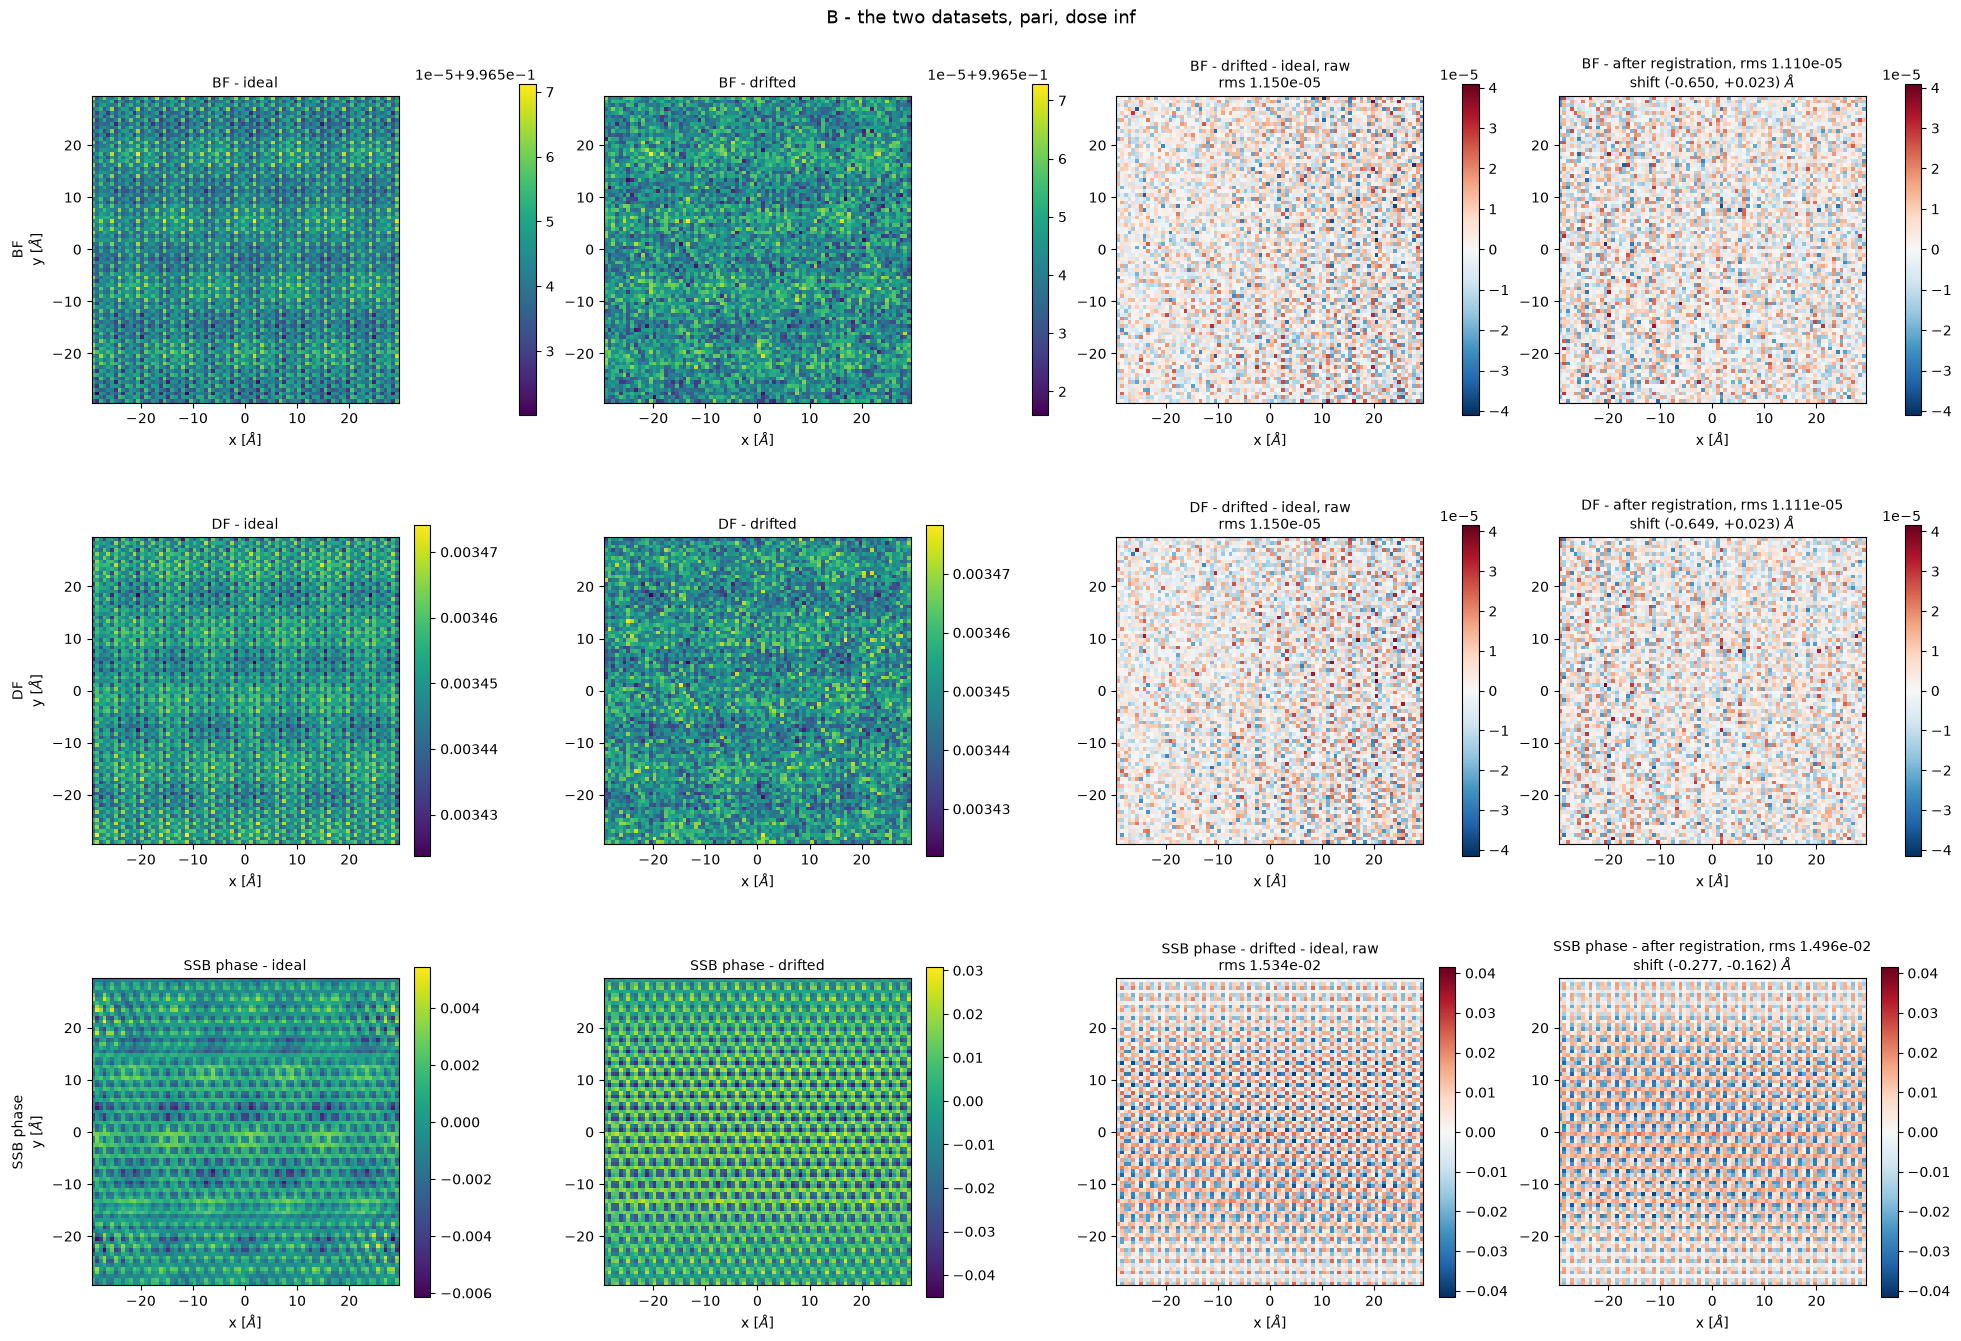

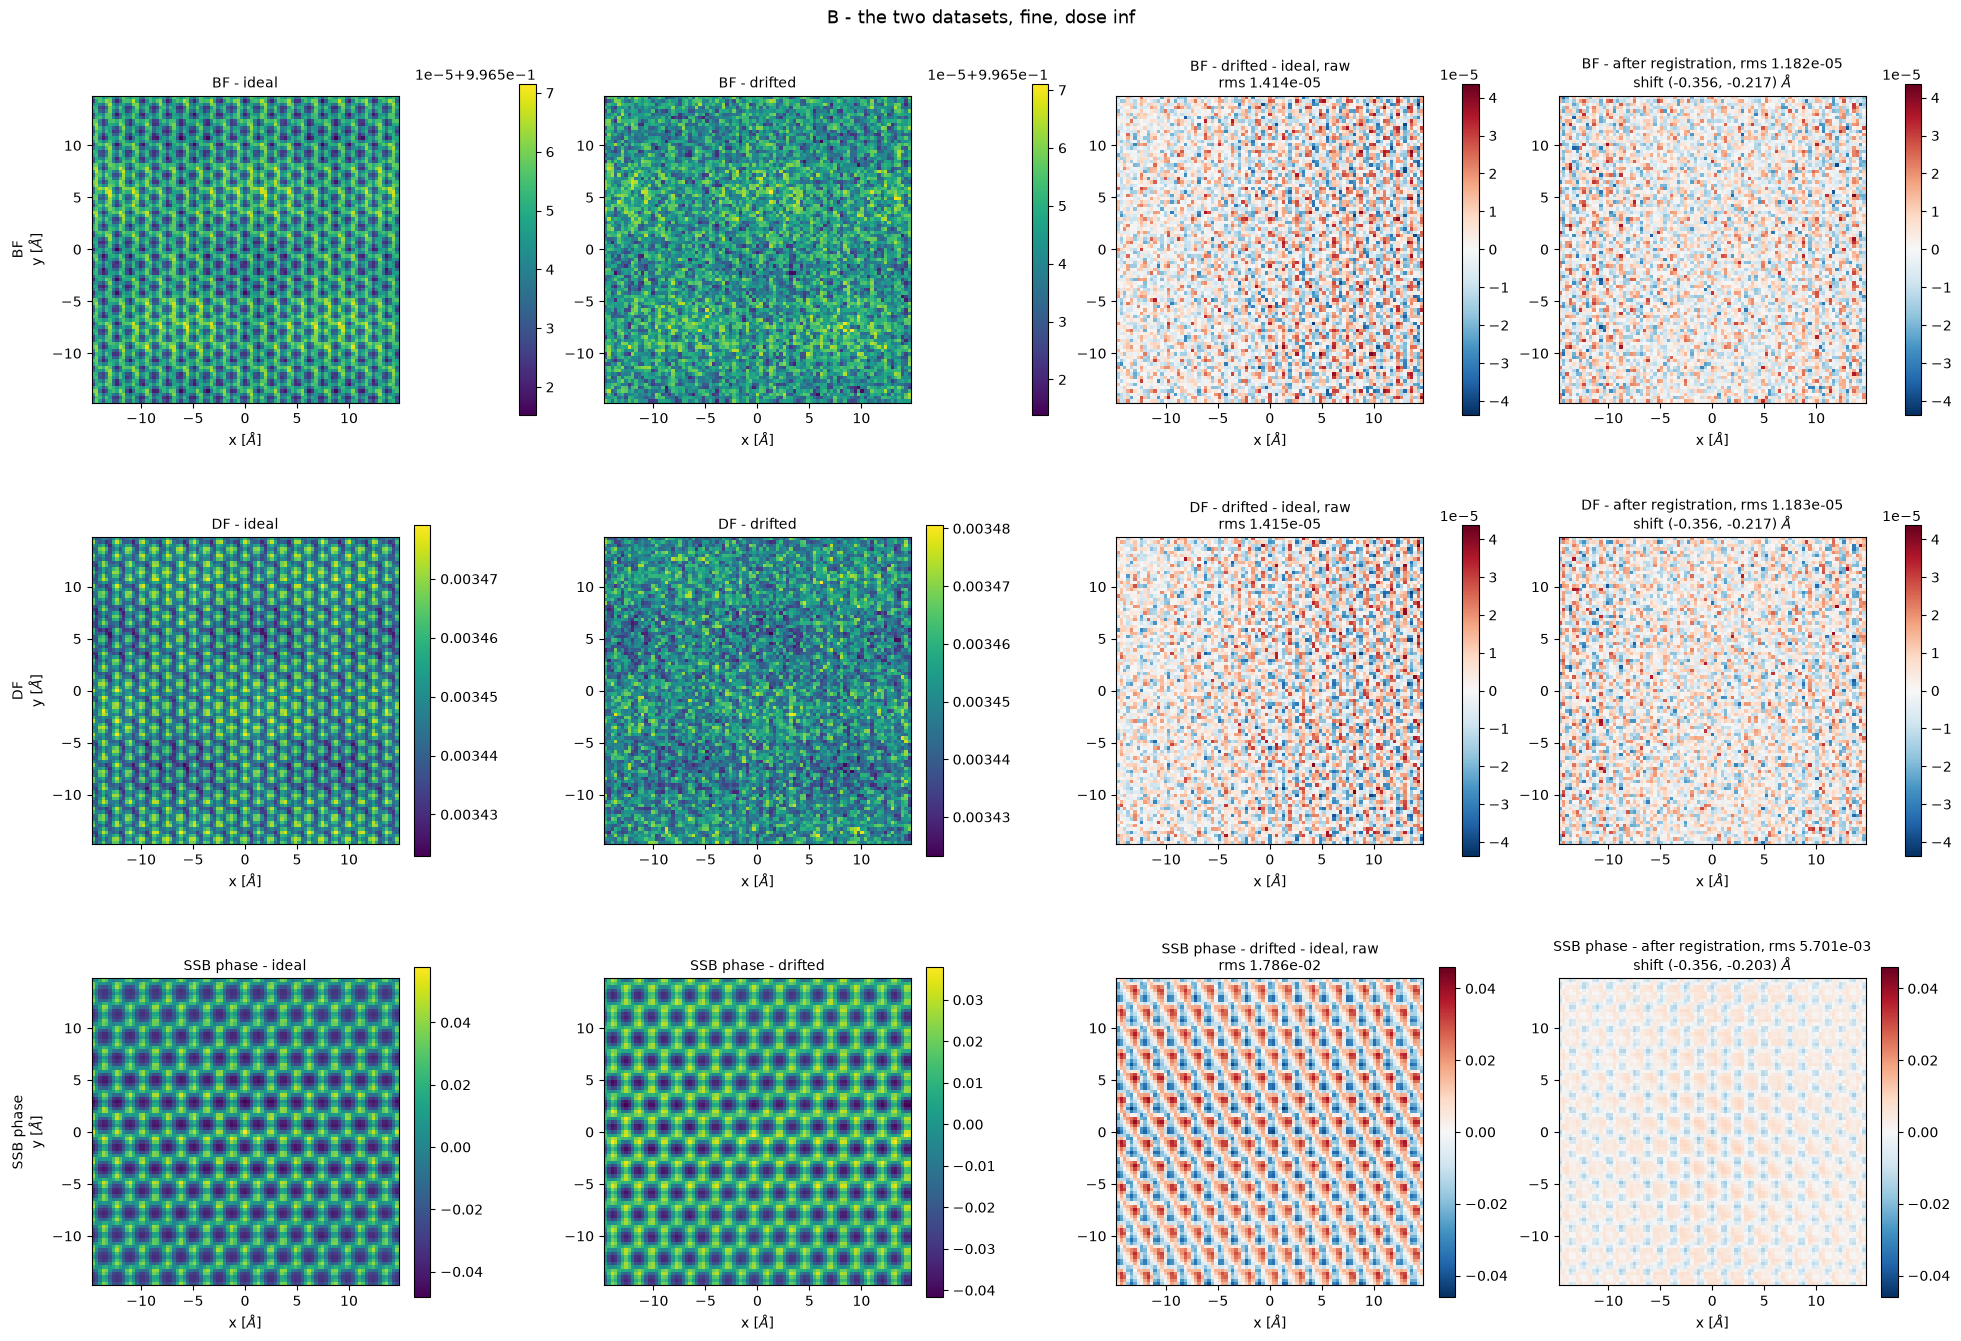

In [13]:
shifts_B = {}
for tag in SCAN_CONFIGS:
    ca = coarse_axis[tag]
    ext = [ca[0], ca[-1], ca[0], ca[-1]]
    step_coarse = 2 * SCAN_CONFIGS[tag]["step_ang"]
    fig, axes = plt.subplots(len(MODALITIES), 4,
                             figsize=(19.5, 4.5 * len(MODALITIES)),
                             constrained_layout=True)
    for row, mod in enumerate(MODALITIES):
        a = images[(tag, "ideal", DIAG_DOSE_KEY)][(mod, "off")]
        b = images[(tag, "drifted", DIAG_DOSE_KEY)][(mod, "off")]
        shift, b_reg = register(a, b, step_coarse)
        shifts_B[(tag, mod)] = shift
        raw, res = b - a, b_reg - a

        for col, (img, title, cmap, sym) in enumerate([
                (a, "ideal", "viridis", False),
                (b, "drifted", "viridis", False),
                (raw, f"drifted - ideal, raw\nrms {raw.std():.3e}", "RdBu_r", True),
                (res, f"after registration, rms {res.std():.3e}\n"
                      f"shift ({shift[0]*step_coarse:+.3f}, {shift[1]*step_coarse:+.3f}) $\\AA$",
                 "RdBu_r", True)]):
            ax = axes[row][col]
            kw = dict(vmin=-np.abs(raw).max(), vmax=np.abs(raw).max()) if sym else {}
            im = ax.imshow(img.T, extent=ext, origin="lower", cmap=cmap, **kw)
            ax.set_title(f"{MODALITY_LABEL[mod]} - {title}", fontsize=10)
            ax.set_xlabel(r"x [$\AA$]")
            if col == 0:
                ax.set_ylabel(f"{MODALITY_LABEL[mod]}\n" + r"y [$\AA$]")
            fig.colorbar(im, ax=ax, shrink=0.8)

    fig.suptitle(f"B - the two datasets, {tag}, dose {DIAG_DOSE_KEY}", fontsize=13)
    plt.show()

### The numbers, at every dose

`contrast` is the peak $|on-off|$ within the 9 Å taper radius over the rms outside
15 Å - how far the excitation stands out of its own background. The ideal column is the
best this geometry can do; the two drifted columns are before and after a global
registration of the channels.

`B shift` is the global displacement between the drifted and the ideal image of the same
channel. The ramp predicts it: the mean of a $0 \to vT$ ramp is $vT/2$, so the expected
magnitude is given in the last row of each block.

In [14]:
print(f"{'tag':5s} {'dose':>4s} {'mod':>4s} | "
      f"{'contrast ideal':>14s} {'drift raw':>10s} {'drift reg':>10s} | "
      f"{'A shift [A]':>22s} | {'B shift [A]':>22s} {'B rms raw':>10s} {'B rms reg':>10s}")
print("-" * 136)

summary = []
for tag in SCAN_CONFIGS:
    step_coarse = 2 * SCAN_CONFIGS[tag]["step_ang"]
    for dose_key in DOSES:
        ideal = images[(tag, "ideal", dose_key)]
        drift = images[(tag, "drifted", dose_key)]
        for mod in MODALITIES:
            d_ideal = ideal[(mod, "on")] - ideal[(mod, "off")]
            d_raw = drift[(mod, "on")] - drift[(mod, "off")]
            sa, on_reg = register(drift[(mod, "off")], drift[(mod, "on")], step_coarse)
            d_reg = on_reg - drift[(mod, "off")]
            sb, b_reg = register(ideal[(mod, "off")], drift[(mod, "off")], step_coarse)
            raw_b = drift[(mod, "off")] - ideal[(mod, "off")]
            res_b = b_reg - ideal[(mod, "off")]
            row = dict(tag=tag, dose=dose_key, mod=mod,
                       c_ideal=excitation_contrast(d_ideal, tag),
                       c_raw=excitation_contrast(d_raw, tag),
                       c_reg=excitation_contrast(d_reg, tag),
                       a_shift=sa * step_coarse, b_shift=sb * step_coarse,
                       b_raw=raw_b.std(), b_reg=res_b.std())
            summary.append(row)
            print(f"{tag:5s} {dose_key:>4s} {mod.upper():>4s} | "
                  f"{row['c_ideal']:14.2f} {row['c_raw']:10.2f} {row['c_reg']:10.2f} | "
                  f"({row['a_shift'][0]:+8.4f},{row['a_shift'][1]:+8.4f}) | "
                  f"({row['b_shift'][0]:+8.4f},{row['b_shift'][1]:+8.4f}) "
                  f"{row['b_raw']:10.3e} {row['b_reg']:10.3e}")
    n_scan = drift_fields[tag]["n_scan"]
    frame_s = n_scan ** 2 * DWELL_S
    mean_ramp = 0.5 * DRIFT_V_ANG_S * frame_s
    print(f"{tag:5s}  predicted B shift magnitude = vT/2 = {mean_ramp:.4f} A "
          f"= {mean_ramp/step_coarse:.3f} coarse px; "
          f"relative on/off jitter sigma = {JITTER_SIGMA_ANG:.3f} A, mean ~ 0")
    print("-" * 136)

tag   dose  mod | contrast ideal  drift raw  drift reg |            A shift [A] |            B shift [A]  B rms raw  B rms reg
----------------------------------------------------------------------------------------------------------------------------------------
pari   inf   BF |           2.28       2.76       2.64 | ( -0.0592, -0.0132) | ( -0.6500, +0.0227)  1.150e-05  1.110e-05
pari   inf   DF |           2.31       2.76       2.64 | ( -0.0581, -0.0139) | ( -0.6485, +0.0227)  1.150e-05  1.111e-05
pari   inf  SSB |           4.58       2.94       2.95 | ( +0.0001, -0.0040) | ( -0.2771, -0.1618)  1.534e-02  1.496e-02
pari   1e6   BF |           3.11       3.93       3.68 | ( +0.0521, +0.1636) | ( -0.5205, -0.0687)  1.601e-04  1.583e-04
pari   1e6   DF |           3.08       3.96       3.74 | ( +0.0294, +0.1560) | ( -0.5368, -0.0724)  1.601e-04  1.582e-04
pari   1e6  SSB |           2.73       3.06       3.48 | ( -1.0226, +0.3639) | ( -0.9859, +0.0053)  2.298e-03  2.258e-03
pari   1e5

## What this says

The run contradicts part of what this notebook predicted before it ran, so read it in
that order: the claim about comparison A held, the claim about comparison B did not.

### A - confirmed

At infinite dose the registration between the two channels finds nothing, as derived:
$(+0.0001, -0.0040)\ \mathrm{\AA}$ for `pari` SSB, $(-0.0021, +0.0028)$ for `fine`. The
ramp cancelled, the jitter has no mean, and there is no shift to remove.

At **finite** dose it does worse than nothing. The reported shifts become spurious and
large - $(-1.02, +0.36)\ \mathrm{\AA}$ for `pari` 1e6 SSB, $(+1.15, +0.16)$ for `fine` 1e5
SSB - and the `pari` 1e5 BF/DF rows sit at exactly $\pm 0.3639\ \mathrm{\AA} = \pm 0.5$
coarse px, which is the parabolic fit hitting its clip on a correlation peak that has gone
flat. So channel-to-channel registration is not merely useless here, it is unstable, and
it invents displacements of order the jitter itself.

### B - refuted

The expectation written above was that B would carry a $vT/2$ translation which
registration would largely remove. **It does not.** `B rms reg` improves on `B rms raw` by
only 1-3% in nearly every row (`pari` inf BF: 1.150e-5 to 1.110e-5). The single exception
is `fine` inf SSB, 1.786e-2 to 5.701e-3.

And the measured displacement does not match the prediction printed in the table:
$0.650\ \mathrm{\AA}$ for `pari` inf BF against $vT/2 = 0.334\ \mathrm{\AA}$, at about
$2^\circ$ rather than the $30^\circ$ the drift was applied at.

Both follow from the same oversight. A ramp that is linear in the slow index is a
**dilation along the slow axis plus a shear across it**, and neither is a translation. The
step from "the best-fit translation equals the mean displacement" to a prediction of
$vT/2$ at $30^\circ$ was an assumption, not a derivation, and the data does not support
it. On a periodic lattice a dilation changes the fringe spacing, which decorrelates the
images rather than displacing them - which is also why the residual barely falls when a
shift is removed.

### The conclusion that survives

**Neither comparison is repaired by global registration**, for two different reasons: the
ramp is common-mode between the channels and so is absent from A altogether, and it is a
shear rather than a translation and so is out of reach of a single shift in B. That is a
stronger statement than the one this notebook set out to make, and it points the same way:
positions have to be refined **per point**. Nothing global will do.

One number worth carrying: the SSB phase images differ between the ideal and drifted
datasets by an rms of 1.5e-2 rad while the images themselves span only about
$\pm 6\times10^{-3}$ rad. Under $\sigma = 0.25\ \mathrm{\AA}$ of jitter the SSB phase
changes by more than its own dynamic range. BF and DF, which integrate over the whole
disc, are far less sensitive (rms 1.2e-5). That ordering is a prediction for notebooks
11-15 and should be checked there rather than assumed.

### Two caveats on the numbers above

* **The contrast metric is noise-sensitive and should not be read as a quality score.**
  Its numerator is $\max|on-off|$ over the pixels inside the taper - an extreme-value
  statistic that grows with noise - so several rows show the *drifted* contrast exceeding
  the ideal one (`pari` inf BF, 2.28 to 2.76), which is not an improvement. Notebook 09
  needs a metric with a fitted or integrated numerator, not a peak, and 19 should reuse it.
* **This diagnostic cannot see a drift larger than $a/2 = 1.253\ \mathrm{\AA}$**, because
  the registration search had to be bounded below the lattice period. At the stressed
  $v = 2\ \mathrm{\AA/s}$ the ramp alone would exceed that. 19 should work from the applied
  field that this notebook saves (`drift_total_ang`, `scan_positions_true`), not from image
  registration.

Carry forward into 11-15: refine positions per point rather than globally, and take the
figure of merit for the block to be how much of the $\sigma = 0.25\ \mathrm{\AA}$ jitter
each method can absorb.